In [146]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob

In [147]:
FILES=glob.glob('../moving_predictions/curves/*')

In [148]:
FILES

['../moving_predictions/curves/Oxygen_Dependence.csv',
 '../moving_predictions/curves/Diarrhea.csv',
 '../moving_predictions/curves/GI_Bleeding.csv',
 '../moving_predictions/curves/Liver_Damage.csv',
 '../moving_predictions/curves/Pulmonary_Hypertension.csv',
 '../moving_predictions/curves/Nausea.csv']

In [149]:
df=pd.read_csv(FILES[0])

In [150]:
df

,fpr,tpr,ppv,acc,npv,LR+,LR-,threshold,tpr_upper,ppv_upper,...,threshold_lower,AUC,AUC_upper,AUC_lower,n_pos,n_neg,n_total,prevalence_in_data,prevalence_preset,prevalence
0,0.000,0.000000,0.905669,0.927509,0.927509,59.919631,1.000000,inf,0.000000,0.915763,...,0.166871,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
1,0.001,0.080744,0.862542,0.931975,0.932879,55.695174,0.920623,0.284464,0.087286,0.872155,...,0.284464,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
2,0.002,0.117440,0.820564,0.933710,0.935324,47.692128,0.884758,0.262648,0.125170,0.830262,...,0.262648,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
3,0.003,0.148181,0.793827,0.934867,0.937369,41.728499,0.854919,0.247035,0.156712,0.803254,...,0.247035,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
4,0.004,0.162339,0.759892,0.935284,0.938308,38.649981,0.841264,0.239982,0.171194,0.769849,...,0.239982,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
996,0.996,0.999905,0.072754,0.076181,1.086261,1.005121,0.000394,0.059854,1.000139,0.072770,...,0.059854,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
997,0.997,0.999929,0.072688,0.075258,1.086633,1.003841,0.000296,0.059853,1.000131,0.072702,...,0.059853,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
998,0.998,0.999953,0.072622,0.074336,1.087005,1.002560,0.000197,0.059853,1.000118,0.072634,...,0.059853,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491
999,0.999,0.999976,0.072557,0.073413,1.087377,1.001280,0.000099,0.059853,1.000093,0.072564,...,0.059853,0.912341,0.917033,0.907649,6663,85252,91915,0.072491,0,0.072491


In [151]:
FILES_=glob.glob('../moving_predictions/*')
FILES_

['../moving_predictions/curves',
 '../moving_predictions/ALL_MARKED_MONTHS.parquet',
 '../moving_predictions/ALL_PREDS_DF.parquet',
 '../moving_predictions/COMBINED.parquet']

In [152]:
pd.read_parquet('../moving_predictions/ALL_MARKED_MONTHS.parquet')

,patient_id,month,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea
0,652137701,0,0.0,0.0,0.0,0.0,0.0,0.0
1,652137701,1,0.0,0.0,0.0,0.0,0.0,0.0
2,652137701,2,0.0,0.0,1.0,0.0,1.0,0.0
3,652137701,3,0.0,0.0,1.0,0.0,0.0,0.0
4,652137701,4,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
1028669,27569657301,32,0.0,0.0,0.0,0.0,0.0,0.0
1028670,27569657301,33,0.0,0.0,0.0,0.0,0.0,1.0
1028671,27569657301,34,0.0,0.0,0.0,0.0,0.0,0.0
1028672,27569657301,35,0.0,0.0,0.0,0.0,0.0,0.0


In [153]:
pf=pd.read_parquet('../moving_predictions/COMBINED.parquet').set_index('patient_id')
pf.columns

Index(['month', 'Liver_Damage', 'Oxygen_Dependence', 'GI_Bleeding',
       'Pulmonary_Hypertension', 'Diarrhea', 'Nausea', 'Liver_Damage_risk',
       'Liver_Damage_ppv', 'Oxygen_Dependence_risk', 'Oxygen_Dependence_ppv',
       'GI_Bleeding_risk', 'GI_Bleeding_ppv', 'Pulmonary_Hypertension_risk',
       'Pulmonary_Hypertension_ppv', 'Diarrhea_risk', 'Diarrhea_ppv',
       'Nausea_risk', 'Nausea_ppv'],
      dtype='object')

In [154]:
pf_=pf.drop(['Liver_Damage_ppv', 'Oxygen_Dependence_ppv','GI_Bleeding_ppv', 
       'Pulmonary_Hypertension_ppv', 'Diarrhea_ppv',
      'Nausea_ppv'],axis=1)
pf__=pf.drop(['Liver_Damage_risk', 'Oxygen_Dependence_risk','GI_Bleeding_risk', 
       'Pulmonary_Hypertension_risk', 'Diarrhea_risk',
      'Nausea_risk'],axis=1)


In [167]:
cf=pf_.drop('month',axis=1).corr()

In [170]:
cf.

,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea,Liver_Damage_risk,Oxygen_Dependence_risk,GI_Bleeding_risk,Pulmonary_Hypertension_risk,Diarrhea_risk,Nausea_risk
Liver_Damage,1.000000,-0.008257,0.005563,0.045995,0.042824,0.007741,-0.010685,-0.022538,-0.017840,2.741479e-04,-1.265497e-03,0.000851
Oxygen_Dependence,-0.008257,1.000000,-0.007951,0.042758,0.020115,0.013697,0.005811,0.042521,0.048335,-5.070676e-03,4.366415e-03,-0.007228
GI_Bleeding,0.005563,-0.007951,1.000000,0.059567,0.103853,0.120278,-0.009786,-0.002175,0.003181,1.592637e-02,2.307521e-02,0.012282
Pulmonary_Hypertension,0.045995,0.042758,0.059567,1.000000,0.025795,0.017808,-0.010857,0.030519,0.042023,1.238544e-01,1.417525e-02,-0.013315
Diarrhea,0.042824,0.020115,0.103853,0.025795,1.000000,0.141725,-0.009451,0.094827,0.063851,-4.337849e-03,1.161949e-02,0.039286
Nausea,0.007741,0.013697,0.120278,0.017808,0.141725,1.000000,0.016459,0.002536,-0.005001,-1.400412e-02,2.684540e-02,0.015341
Liver_Damage_risk,-0.010685,0.005811,-0.009786,-0.010857,-0.009451,0.016459,1.000000,0.129797,0.234878,6.909355e-03,1.371083e-01,0.138393
Oxygen_Dependence_risk,-0.022538,0.042521,-0.002175,0.030519,0.094827,0.002536,0.129797,1.000000,0.279109,1.385661e-01,4.250876e-02,0.063229
GI_Bleeding_risk,-0.017840,0.048335,0.003181,0.042023,0.063851,-0.005001,0.234878,0.279109,1.000000,3.083411e-02,1.690614e-01,0.186492
Pulmonary_Hypertension_risk,0.000274,-0.005071,0.015926,0.123854,-0.004338,-0.014004,0.006909,0.138566,0.030834,1.000000e+00,-4.516318e-07,-0.010544


<Axes: >

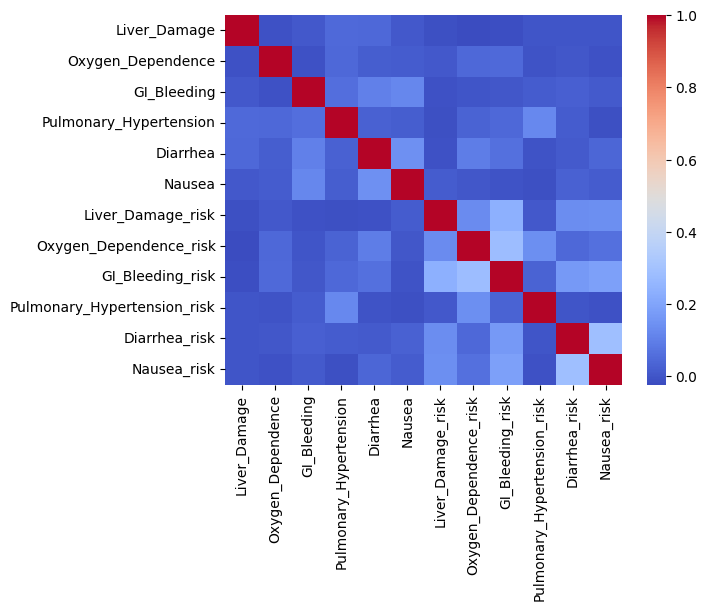

In [169]:
sns.heatmap(cf,cmap='coolwarm')

<Axes: >

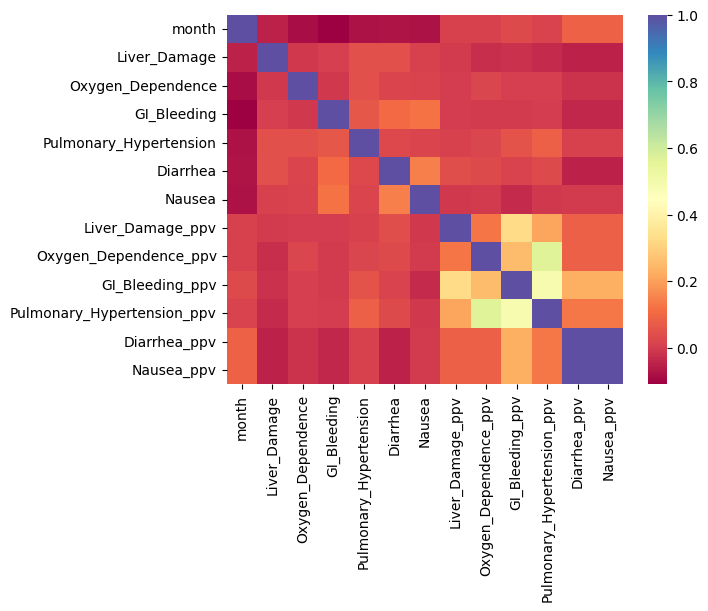

In [160]:
sns.heatmap((pf__>0.2).corr(),cmap='Spectral')

In [161]:
pf__.sample(100)

,month,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea,Liver_Damage_ppv,Oxygen_Dependence_ppv,GI_Bleeding_ppv,Pulmonary_Hypertension_ppv,Diarrhea_ppv,Nausea_ppv
patient_id,,,,,,,,,,,,,
1973004902,6,0.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
591688001,30,0.0,0.0,0.0,0.0,0.0,0.0,0.097192,0.085559,0.197413,0.135005,0.218142,0.277234
623067701,3,0.0,0.0,0.0,0.0,0.0,0.0,0.138966,0.072491,0.201514,0.111519,0.232701,0.285229
1261986001,16,0.0,0.0,0.0,0.0,0.0,0.0,0.112633,0.072491,0.228282,0.137146,0.256893,0.318732
136102601,7,0.0,0.0,0.0,0.0,0.0,0.0,0.136359,0.357237,0.202104,0.293677,0.313371,0.413228
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1262281601,14,0.0,0.0,0.0,0.0,0.0,0.0,0.109772,0.072491,0.149737,0.102913,0.226852,0.296484
1496798101,7,0.0,0.0,0.0,0.0,0.0,0.0,0.116947,0.072491,0.161812,0.102913,0.258693,0.359949
609979001,16,0.0,0.0,0.0,0.0,0.0,0.0,0.103348,0.072491,0.192817,0.157059,0.223027,0.280217


In [162]:
pf__.index.values

array([      84401,       84401,       84401, ..., 33326895201,
       33326895201, 33326895201], shape=(10841,))

In [163]:
pf__.loc[['34199516101',:]]

SyntaxError: invalid syntax (3705010877.py, line 1)

In [164]:
pf.loc[[960434801], :]#.set_index('month').mean(axis=1).plot()



KeyError: "None of [Index([960434801], dtype='object', name='patient_id')] are in the [index]"

In [165]:
xf=pf_#.drop('month',axis=1)

In [166]:
pf_.groupby('month').median().corr()

,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea,Liver_Damage_risk,Oxygen_Dependence_risk,GI_Bleeding_risk,Pulmonary_Hypertension_risk,Diarrhea_risk,Nausea_risk
Liver_Damage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oxygen_Dependence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GI_Bleeding,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pulmonary_Hypertension,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diarrhea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nausea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Liver_Damage_risk,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.254255,0.960157,0.923386,0.961943,0.938407
Oxygen_Dependence_risk,NaN,NaN,NaN,NaN,NaN,NaN,0.254255,1.000000,0.310417,0.213459,0.303847,0.285211
GI_Bleeding_risk,NaN,NaN,NaN,NaN,NaN,NaN,0.960157,0.310417,1.000000,0.947572,0.962021,0.963668
Pulmonary_Hypertension_risk,NaN,NaN,NaN,NaN,NaN,NaN,0.923386,0.213459,0.947572,1.000000,0.956273,0.962343


In [94]:
wf=((xf-xf.mean())/xf.std())

In [110]:
a=wf.Oxygen_Dependence.values
b= wf.Oxygen_Dependence_risk

In [111]:
np.corrcoef(a,b.values)

array([[ 1., nan],
       [nan, nan]])

In [112]:
pd.DataFrame({'a':a,'b':b.values}).corr()

,a,b
a,1.00000,0.00276
b,0.00276,1.00000


In [125]:
pf.reset_index().patient_id.value_counts()

patient_id
502            37
26401          37
64301          37
84401          37
119701         37
               ..
34187995802    37
34189576401    37
34190598801    37
34196920901    37
34199516101    37
Name: count, Length: 27802, dtype: int64

In [136]:
RISK=[x for x  in pf.columns if 'risk' in x]
NH_=[x for x  in pf.columns if 'risk' not in x]
NH=[x for x  in NH_ if 'ppv' not in x]


<Axes: xlabel='month'>

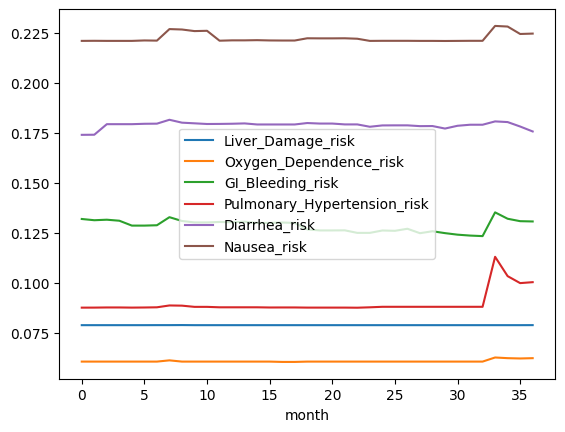

In [133]:
pf.loc[119701,:].set_index('month')[RISK].plot()#.corr()

In [138]:
pf.loc[119701,:].set_index('month')

,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea,Liver_Damage_risk,Liver_Damage_ppv,Oxygen_Dependence_risk,Oxygen_Dependence_ppv,GI_Bleeding_risk,GI_Bleeding_ppv,Pulmonary_Hypertension_risk,Pulmonary_Hypertension_ppv,Diarrhea_risk,Diarrhea_ppv,Nausea_risk,Nausea_ppv
month,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0.078788,0.097192,0.060569,0.122116,0.131892,0.210651,0.087554,0.130338,0.173979,0.235668,0.220968,0.279464
1,0,0,1,0,0,0,0.078788,0.097192,0.060569,0.122116,0.131274,0.208088,0.087571,0.130767,0.174034,0.235829,0.221010,0.279840
2,0,0,0,0,0,0,0.078788,0.097192,0.060569,0.122116,0.131532,0.209091,0.087645,0.132058,0.179312,0.251886,0.220968,0.279464
3,0,0,0,0,0,0,0.078788,0.097192,0.060569,0.122116,0.131024,0.207018,0.087645,0.132058,0.179312,0.251886,0.220968,0.279464
4,0,0,0,0,0,0,0.078788,0.097192,0.060569,0.122116,0.128585,0.197227,0.087571,0.130767,0.179312,0.251886,0.220968,0.279464
5,0,0,0,0,0,0,0.078788,0.097192,0.060569,0.122116,0.128585,0.197227,0.087627,0.131771,0.179508,0.252450,0.221187,0.281545
6,0,0,0,0,0,0,0.078807,0.097800,0.060569,0.122116,0.128759,0.197972,0.087724,0.133367,0.179572,0.252638,0.221100,0.280784
7,0,0,0,0,0,0,0.078807,0.097800,0.061188,0.133176,0.132795,0.214176,0.088643,0.146171,0.181513,0.259098,0.226871,0.293267
8,0,0,0,0,0,0,0.078839,0.098886,0.060569,0.122116,0.130894,0.206594,0.088549,0.144962,0.180064,0.254355,0.226661,0.292888


In [145]:
pf[NH].groupby('month').sum()#.sum(axis=1)#.values

,Liver_Damage,Oxygen_Dependence,GI_Bleeding,Pulmonary_Hypertension,Diarrhea,Nausea
month,,,,,,
0,0,0,0,0,0,0
1,4387,3179,5224,4628,6804,8346
2,0,0,0,0,0,0
3,0,0,0,0,0,0
4,0,0,0,0,0,0
5,0,0,0,0,0,0
6,0,0,0,0,0,0
7,0,0,0,0,0,0
8,0,0,0,0,0,0
